In [38]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [39]:
class CricketState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    strike_rate : float
    balls_per_boundary : float 
    boundary_percentage : float
    summary : str

In [ ]:
def cal_strike_rate(state : CricketState) -> CricketState:
    state["strike_rate"] = (state["runs"] / state["balls"]) *  100
    return {"strike_rate" : state["strike_rate"]} # Partial state update (If we will send the entire state it will give error)

In [41]:
def cal_balls_per_boundary(state : CricketState) -> CricketState:
    state["balls_per_boundary"] = state["balls"] / (state["fours"] + state["sixes"])
    return {"balls_per_boundary" : state["balls_per_boundary"]}

In [42]:
def cal_boundary_percentage(state : CricketState) -> CricketState:
    state["boundary_percentage"] = ((state['fours'] * 4) + (state['sixes'] * 6))/state['runs']*100
    return {"boundary_percentage" : state["boundary_percentage"]}

In [43]:
def print_summary(state : CricketState) -> CricketState:
    state["summary"] = f"""
    Strike Rate : {state["strike_rate"]} \n
    Balls per Boundary : {state["balls_per_boundary"]} \ng
    Boundary Percentage : {state["boundary_percentage"]}
    """
    return {"summary" : state["summary"]}

In [44]:
graph = StateGraph(CricketState)
graph.add_node("strike_rate", cal_strike_rate)
graph.add_node("balls_per_boundary", cal_balls_per_boundary)
graph.add_node("boundary_percentage", cal_boundary_percentage)
graph.add_node("summary", print_summary)

In [45]:
graph.add_edge(START, "strike_rate")
graph.add_edge(START, "balls_per_boundary")
graph.add_edge(START, "boundary_percentage")

graph.add_edge("strike_rate", "summary")
graph.add_edge("balls_per_boundary", "summary")
graph.add_edge("boundary_percentage", "summary")

graph.add_edge("summary", END)

In [46]:
workflow = graph.compile()

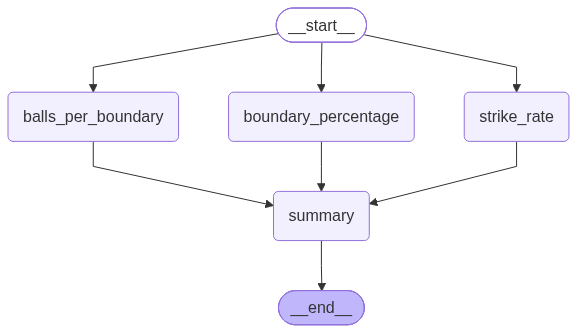

In [47]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [48]:
initial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

final_state = workflow.invoke(initial_state)

In [49]:
print(final_state)

{'runs': 100, 'balls': 50, 'fours': 6, 'sixes': 4, 'strike_rate': 200.0, 'balls_per_boundary': 5.0, 'boundary_percentage': 48.0, 'summary': '\n    Strike Rate : 200.0 \n\n    Balls per Boundary : 5.0 \ng\n    Boundary Percentage : 48.0\n    '}
